<a href="https://colab.research.google.com/github/atman500/atman500/blob/main/Tree_Decision_multiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
from google.colab import files

In [2]:
upload=files.upload()

Saving bank.csv to bank.csv


In [4]:
df=pd.read_csv("bank.csv",sep=';')
print(df.head())

   age         job  marital  education default  balance housing loan  contact  \
0   59      admin.  married  secondary      no     2343     yes   no  unknown   
1   56      admin.  married  secondary      no       45      no   no  unknown   
2   41  technician  married  secondary      no     1270     yes   no  unknown   
3   55    services  married  secondary      no     2476     yes   no  unknown   
4   54      admin.  married   tertiary      no      184      no   no  unknown   

   day month  duration  campaign  pdays  previous poutcome deposit  
0    5   may      1042         1     -1         0  unknown     yes  
1    5   may      1467         1     -1         0  unknown     yes  
2    5   may      1389         1     -1         0  unknown     yes  
3    5   may       579         1     -1         0  unknown     yes  
4    5   may       673         2     -1         0  unknown     yes  


In [7]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

Step 1. Explore the dataset

In [9]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget variable distribution:")
print(df["deposit"].value_counts())

Dataset dimensions: (11162, 17)

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 n

Step 2. Define the input variables and target variable

In [10]:
# Input variables
X = df.drop(columns=["deposit", "duration"])

# Target variable
y = df["deposit"].map({"no": 0, "yes": 1})

print("Input variables:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.value_counts())

Input variables:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Target variable:
deposit
0    5873
1    5289
Name: count, dtype: int64


Step 3. Convert categorical variables into numerical variables

In [11]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoded dataset dimensions:", X.shape)
print(X.head())

Encoded dataset dimensions: (11162, 41)
   age  balance  day  campaign  pdays  previous  job_blue-collar  \
0   59     2343    5         1     -1         0                0   
1   56       45    5         1     -1         0                0   
2   41     1270    5         1     -1         0                0   
3   55     2476    5         1     -1         0                0   
4   54      184    5         2     -1         0                0   

   job_entrepreneur  job_housemaid  job_management  ...  month_jul  month_jun  \
0                 0              0               0  ...          0          0   
1                 0              0               0  ...          0          0   
2                 0              0               0  ...          0          0   
3                 0              0               0  ...          0          0   
4                 0              0               0  ...          0          0   

   month_mar  month_may  month_nov  month_oct  month_sep  poutco

Step 4. Divide the dataset into training and testing sets

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

Training observations: 8929
Testing observations: 2233


Step 5. Build the Decision Tree using multiple variables

In [13]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


Step 6. Predict the target variable

In [14]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results.head(10))

   Actual  Predicted
0       0          1
1       1          1
2       0          1
3       0          0
4       1          0
5       0          0
6       0          1
7       1          0
8       1          1
9       1          0


Step 7. Evaluate the model

In [15]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No deposit", "Deposit"],
    zero_division=0
))

Accuracy: 0.6771

Confusion Matrix:
[[908 267]
 [454 604]]

Classification Report:
              precision    recall  f1-score   support

  No deposit       0.67      0.77      0.72      1175
     Deposit       0.69      0.57      0.63      1058

    accuracy                           0.68      2233
   macro avg       0.68      0.67      0.67      2233
weighted avg       0.68      0.68      0.67      2233



Step 8. Visualize the Decision Tree

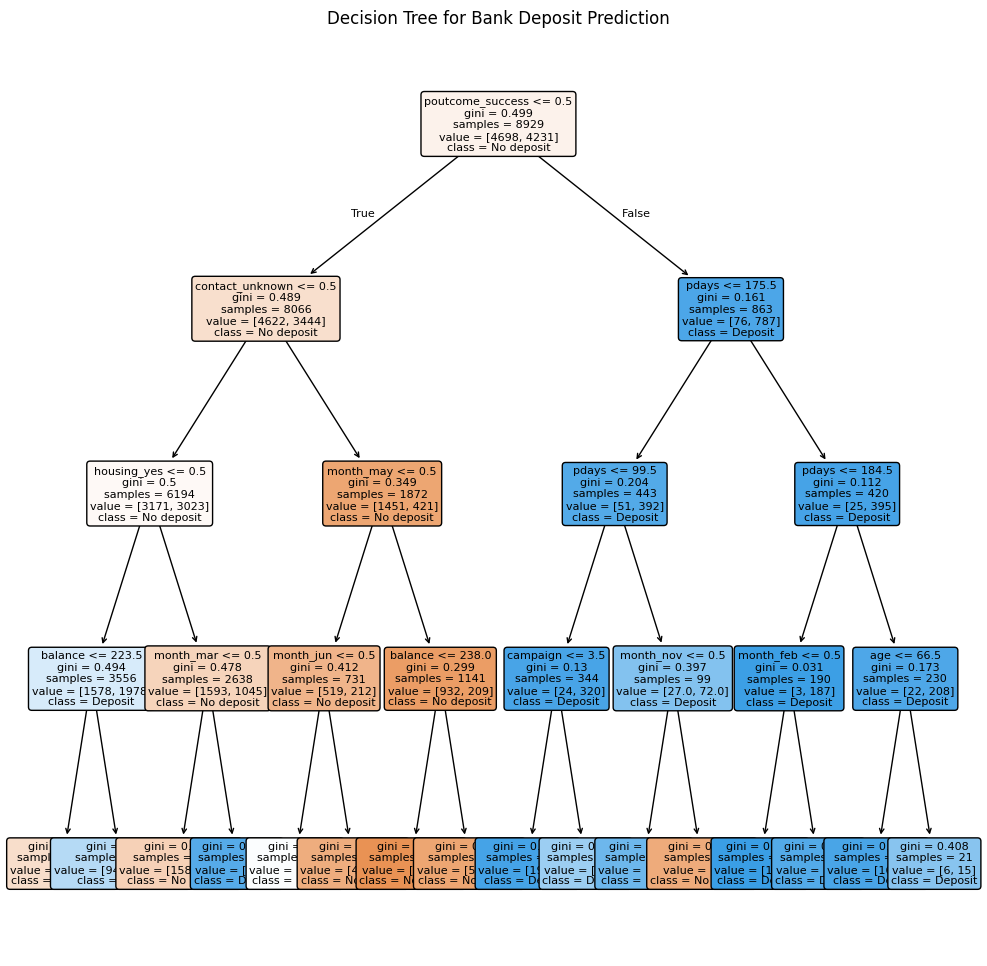

In [18]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(12, 12))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No deposit", "Deposit"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Bank Deposit Prediction")
plt.show()

**Final Interpretation**

Final Interpretation:
**1. Overall Accuracy: 67.71%**
What this means: The model correctly predicts whether a client will subscribe to a term deposit (deposit) in approximately 67.7% of cases.
Context: Because the dataset has a relatively balanced distribution of the target variable (5,873 "no" vs. 5,289 "yes"), a baseline random guess or majority-class guess would yield around 52.6% accuracy. At 67.7%, your model performs significantly better than random guessing, though there is still room for optimization.

**2. Confusion Matrix Analysis**
Out of 2,233 total test observations, the model's predictions break down as follows:

True Negatives (908): The model correctly predicted 908 clients who did not subscribe to the deposit.
True Positives (604): The model correctly predicted 604 clients who did subscribe to the deposit.
False Positives (267): The model predicted 267 clients would subscribe, but they actually did not (Type I Error). In marketing, targeting these clients leads to wasted resources/calls.
False Negatives (454): The model predicted 454 clients would not subscribe, but they actually did (Type II Error). These represent lost opportunities—clients who would have subscribed but whom the bank failed to contact.

**3. Classification Report Metrics**
Precision (How accurate are the positive predictions?)
No Deposit (67%): When the model predicts a client will not subscribe, it is correct 67% of the time.
Deposit (69%): When the model predicts a client will subscribe, it is correct 69% of the time. This is a decent rate for marketing campaigns, meaning about 7 out of 10 targeted clients will convert.
Recall / Sensitivity (How many of the actual targets did we find?)
No Deposit (77%): The model is strong at identifying non-subscribers, capturing 77% of all clients who did not subscribe.
Deposit (57%): The model is weak at capturing potential subscribers, missing 43% of actual buyers (False Negatives).
F1-Score (The balance between Precision & Recall)
No Deposit (0.72) vs. Deposit (0.63): The model is significantly better at predicting who will not subscribe than predicting who will subscribe.

**4. Key Business Takeaway**
By dropping the duration column in Step 2, you made a very realistic model (since you don't know the call duration before making the call). However, because duration is the strongest predictor in bank marketing data, your model must rely on demographic and campaign history instead.

To improve results, you could look into:

Balancing the classification threshold to favor Recall (catching more of those 454 missed subscribers).
Engineering new features from age or balance.
Trying a more robust model like Random Forests or Gradient Boosting.
Here is a complete, structured interpretation of the final predictive results for your Decision Tree model:

**1. Overall Accuracy: 67.71%**
What this means: The model correctly predicts whether a client will subscribe to a term deposit (deposit) in approximately 68 out of every 100 cases.
Interpretation: This is a solid baseline performance. Since the target distribution is relatively balanced (~53% 'no' vs. ~47% 'yes'), a baseline model guessing the majority class would yield roughly 52.6% accuracy. Your model represents a significant, 15% absolute improvement over random guessing.
2. Confusion Matrix Analysis
Out of 2,233 total clients in the test set, your model's predictions are divided as follows:

True Negatives (908): The model correctly identified 908 clients who did not subscribe.
True Positives (604): The model correctly identified 604 clients who did subscribe.
False Positives (267) [Type I Error]: The model predicted 267 clients would subscribe, but they actually did not.
Marketing Impact: Wasted outbound resources, as your team will call clients who are highly unlikely to purchase.
False Negatives (454) [Type II Error]: The model predicted 454 clients would not subscribe, but they actually did.
Marketing Impact: Missed opportunities. These represent potential revenue from clients who would have bought the product if they had been contacted.

**3. Classification Report Breakdown**
Precision (Reliability of positive predictions)
No Deposit (67%): When the model labels a client as "won't subscribe," it is correct 67% of the time.
Deposit (69%): When the model labels a client as "will subscribe," it is correct 69% of the time. This is quite decent; a campaign targeting only this "Deposit" group will have a solid 69% conversion rate.
Recall (Coverage / Capture Rate)
No Deposit (77%): The model is highly effective at filtering out uninterested clients, capturing 77% of those who will not buy.
Deposit (57%): This is the model's main weakness. It only manages to find 57% of the actual buyers, leaving 43% of interested clients uncontacted.
F1-Score (The overall balance)
No Deposit (0.72) vs. Deposit (0.63): Because of the lower recall for positive buyers, the model is noticeably better at identifying and predicting non-subscribers than subscribers.

**4. Strategic Business Insights**
The 'Duration' Trade-Off: In Step 2, you dropped duration (the length of the last call). While this reduces overall performance metrics compared to benchmark sets, this was the correct decision. In a real-world scenario, you do not know the call duration before the call starts. Your model is a highly realistic predictor because it relies purely on client demographics, bank history, and campaign metrics.
Actionable Improvement: Since missing a hot lead (False Negative) is usually costlier than calling an uninterested lead (False Positive), you may want to optimize the model's decision threshold to favor Recall for the "Deposit" class, or move toward ensemble methods (like Random Forest) to capture more than 57% of potential subscribers.
